In [1]:
library(dplyr)
library(Seurat)
library(ggplot2)
library(scDblFinder)
library(SingleCellExperiment)
library(patchwork)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘matrixStats’


The following object is masked from ‘package:dplyr’:

    count



Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colColl

In [2]:
proc_path = '../ProcessedData'
proc_files <- list.files(proc_path, full.names = TRUE, pattern = "_P01.rds$|_P02.rds$|_P03.rds$|_P06.rds$")

processed_files <- lapply(proc_files, function(file){
    readRDS(file)
})

names(processed_files) <- sub(
    ".rds$",
    "",
    basename(proc_files)
)

In [3]:
for(i in seq_along(processed_files)) {

    sample_name <- names(processed_files)[i]

    if(grepl("_P01$|_P02$", sample_name)) {
        processed_files[[i]]$treatment <- "Untreated"
    }

    if(grepl("_P03$|_P06$", sample_name)) {
        processed_files[[i]]$treatment <- "Treated"
    }
}

In [4]:
sample_summary <- data.frame(
    sample = names(processed_files),
    features = sapply(processed_files, nrow),
    cells = sapply(processed_files, ncol)
)

sample_summary

,sample,features,cells
,<chr>,<dbl>,<dbl>
GSM6204109_P01,GSM6204109_P01,23650,4680
GSM6204110_P02,GSM6204110_P02,23307,3340
GSM6204111_P03,GSM6204111_P03,25177,14142
GSM6204114_P06,GSM6204114_P06,22080,1110


In [5]:
for(i in seq_along(processed_files)){
    print(processed_files[[i]])
    break
}

An object of class Seurat 
23650 features across 4680 samples within 1 assay 
Active assay: RNA (23650 features, 2000 variable features)
 2 layers present: counts, data


In [6]:
sum(sapply(processed_files, ncol))

[1] 23272

In [7]:
integrated_features = SelectIntegrationFeatures(object.list = processed_files, nFeatures=2000)

In [8]:
length(integrated_features)

[1] 2000

In [9]:
anchors <- FindIntegrationAnchors(object.list=processed_files, anchor.features = integrated_features, reduction="cca", dims=1:30)

Warning message in CheckDuplicateCellNames(object.list = object.list):
“Some cell names are duplicated across objects provided. Renaming to enforce unique cell names.”
Scaling features for provided objects

Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 7627 anchors

Filtering anchors

	Retained 5297 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 13216 anchors

Filtering anchors

	Retained 5073 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 9367 anchors

Filtering anchors

	Retained 2712 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3936 anchors

Filtering anchors

	Retained 3289 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3781 anchors

Filtering anchors

	Retained 3151 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 4133 anchors

F

In [10]:
saveRDS(
    anchors,
    file = "../ProcessedData/integration_anchors.rds",
    compress = FALSE
)

In [11]:
file.exists("../ProcessedData/integration_anchors.rds")

[1] TRUE

In [12]:
rm(processed_files)
gc()

,used,(Mb),gc trigger,(Mb),limit (Mb),max used,(Mb)
Ncells,12238031,653.6,17940491,958.2,NA,17940491,958.2
Vcells,1435152349,10949.4,2141926116,16341.6,16384,2141926116,16341.6


In [15]:
rm(anchors)
gc()

,used,(Mb),gc trigger,(Mb),limit (Mb),max used,(Mb)
Ncells,12061865,644.2,17940491,958.2,NA,17940491,958.2
Vcells,20844348,159.1,1713540893,13073.3,16384,2141926116,16341.6


In [2]:
anchors <- readRDS(
    "../ProcessedData/integration_anchors.rds"
)

In [10]:
pdac_integrated <- IntegrateData(anchorset = anchors, dims = 1:30)
saveRDS(pdac_integrated, '../ProcessedData/pdac_integrated.rds', compress=FALSE)

Merging dataset 4 into 1

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 2 into 1 4

Extracting anchors for merged samples

Finding integration vectors

Warning message:
“Different cells in new layer data than already exists for scale.data”
Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 1 4 2 into 3

Extracting anchors for merged samples

Finding integration vectors

Warning message:
“Different cells in new layer data than already exists for scale.data”
Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”


In [11]:
DefaultAssay(pdac_integrated) <- "integrated"

In [12]:
pdac_integrated <- ScaleData(pdac_integrated, verbose = FALSE)

In [13]:
pdac_integrated <- RunPCA(object = pdac_integrated, npcs = 30, verbose = FALSE)

In [14]:
pdac_integrated <- FindNeighbors(object = pdac_integrated, dims=1:30)

Computing nearest neighbor graph



Computing SNN



In [15]:
resolutions <- c(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)

for(res in resolutions){
    pdac_integrated <- FindClusters(pdac_integrated, resolution=res, algorithm=3, verbose=FALSE)
}

In [16]:
grep(
    "integrated_snn_res",
    colnames(pdac_integrated@meta.data),
    value = TRUE
)

[1] "integrated_snn_res.0.1" "integrated_snn_res.0.2" "integrated_snn_res.0.3"
 [4] "integrated_snn_res.0.4" "integrated_snn_res.0.5" "integrated_snn_res.0.6"
 [7] "integrated_snn_res.0.7" "integrated_snn_res.0.8" "integrated_snn_res.0.9"
[10] "integrated_snn_res.1"

In [18]:
pdac_integrated <- RunUMAP(
    pdac_integrated,
    dims = 1:30,
    n.neighbors = 30,
    min.dist = 0.3
)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
16:16:52 UMAP embedding parameters a = 0.9922 b = 1.112

16:16:52 Read 23272 rows and found 30 numeric columns

16:16:52 Using Annoy for neighbor search, n_neighbors = 30

16:16:52 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:16:54 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//Rtmp1dqutY/filed6141793d5e

16:16:54 Searching Annoy index using 1 thread, search_k = 3000

16:16:58 Annoy recall = 100%

16:16:59 Commencing smooth kNN distance calibrat

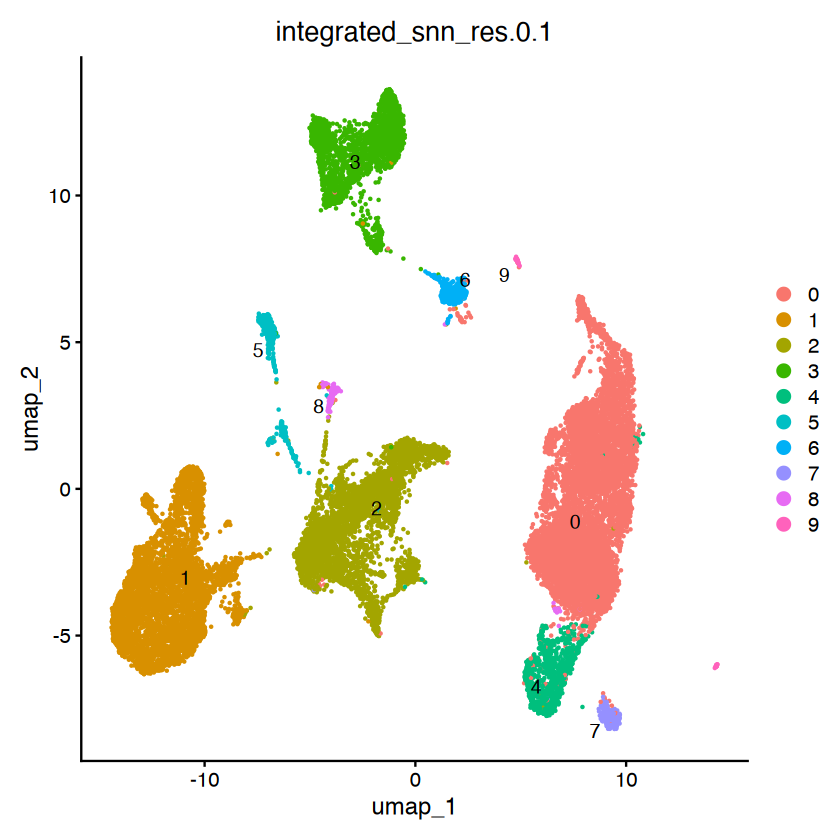

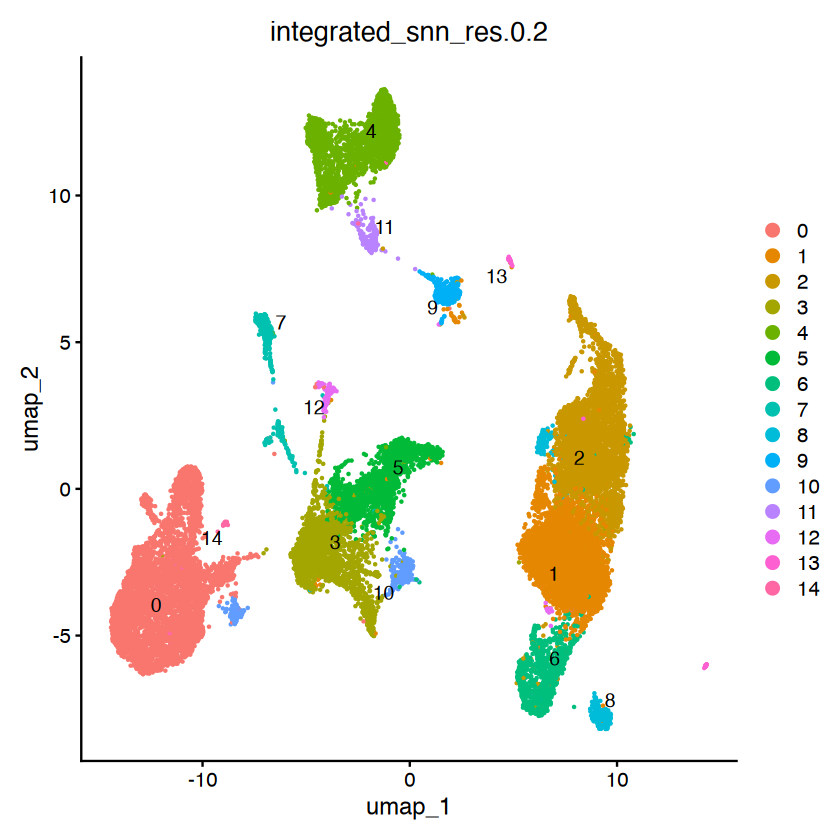

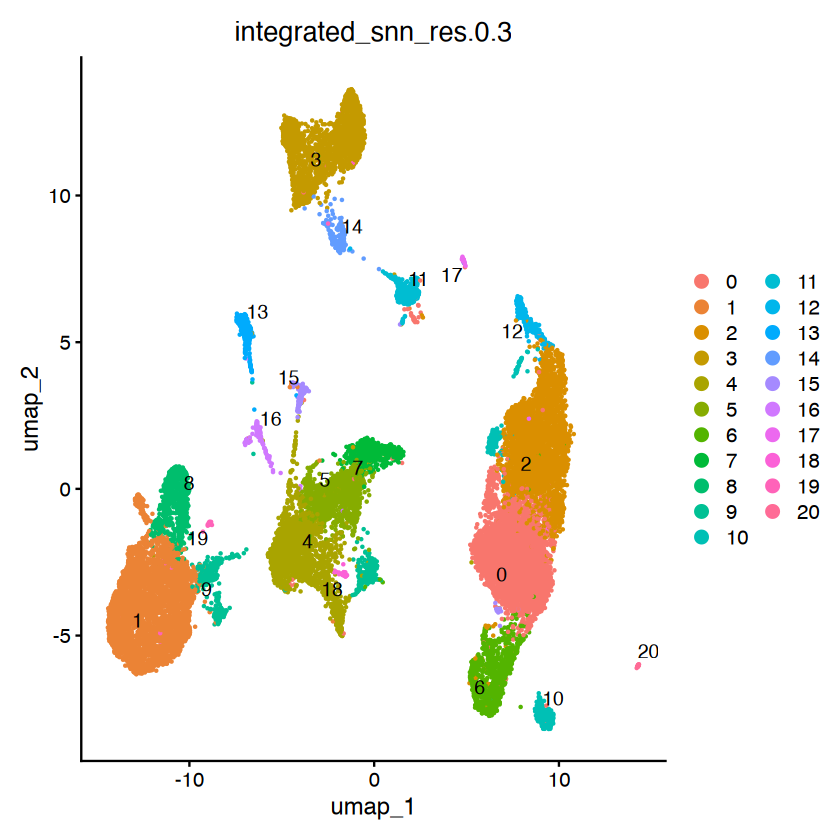

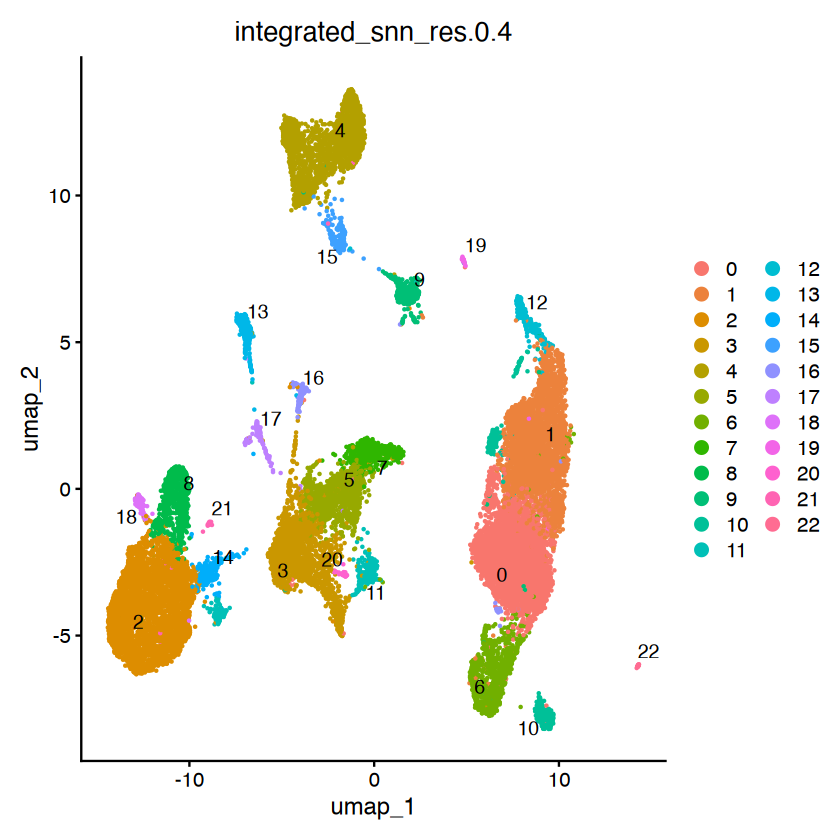

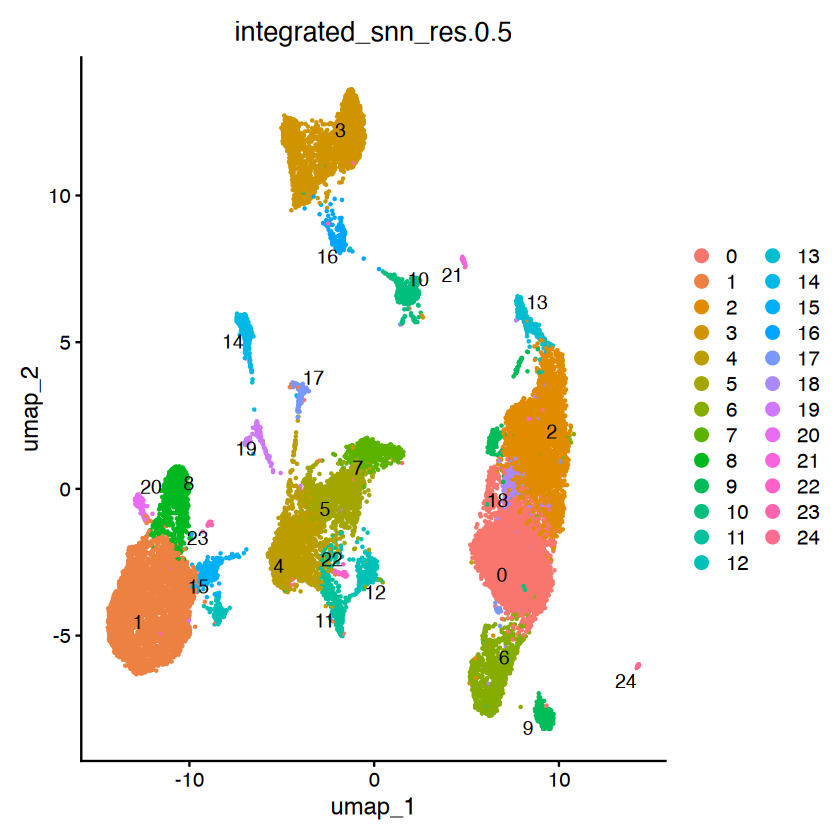

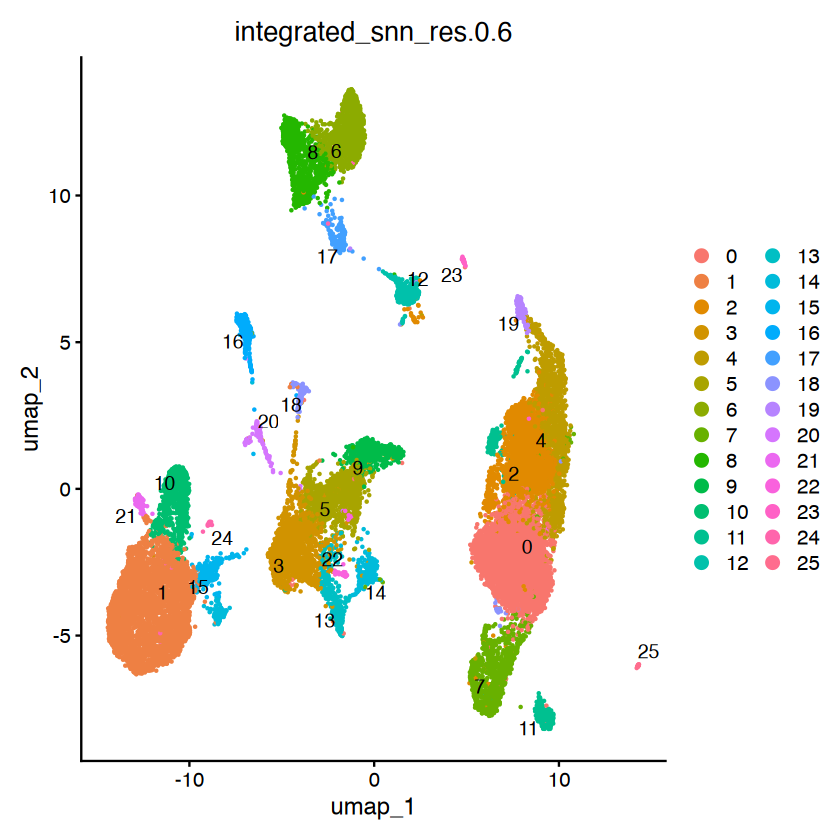

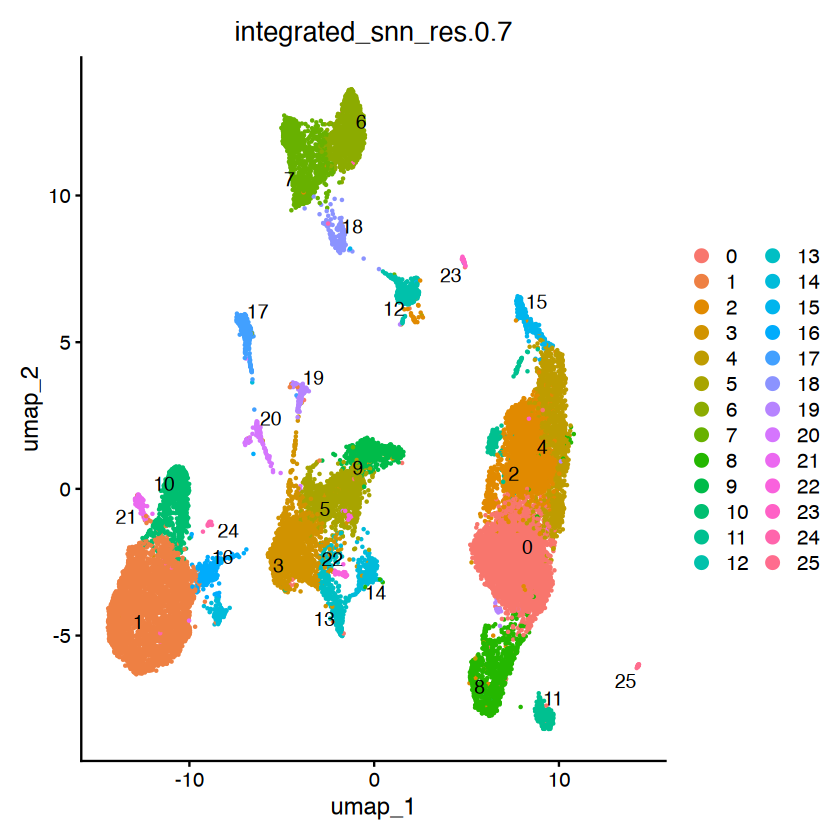

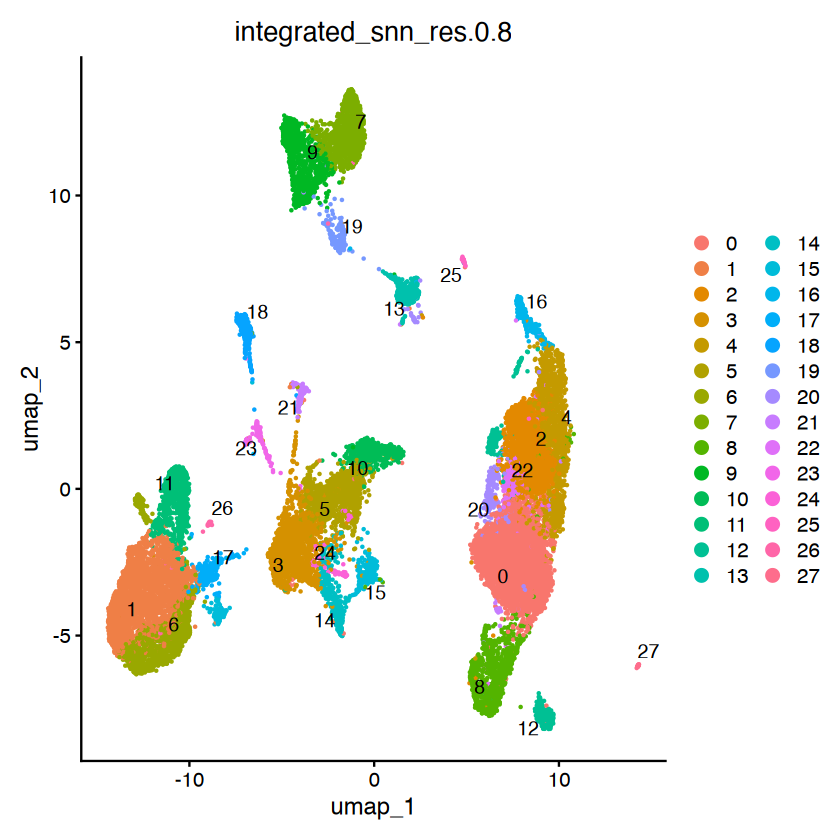

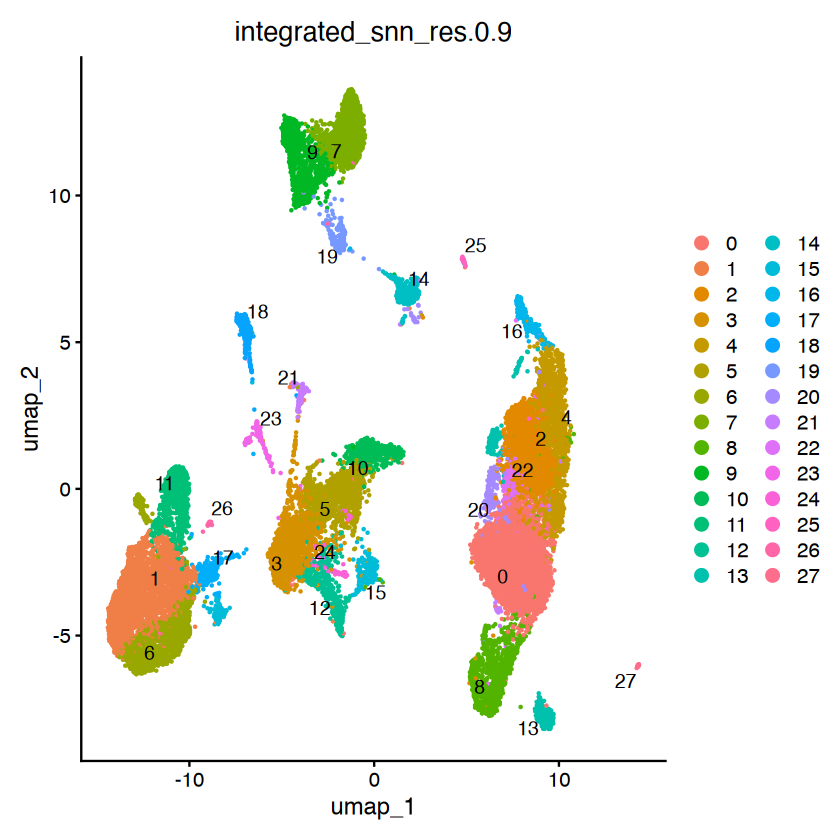

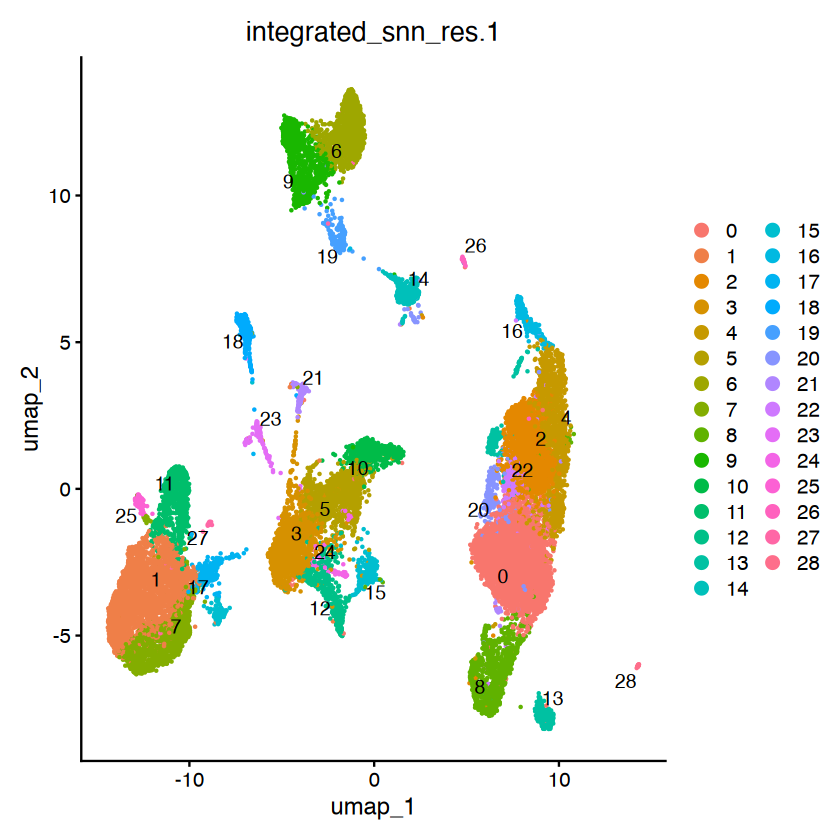

In [19]:
resolution_cols <- paste0(
    "integrated_snn_res.",
    c(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1)
)

for (res in resolution_cols) {

    p <- DimPlot(
        pdac_integrated,
        reduction = "umap",
        group.by = res,
        label = TRUE,
        repel = TRUE
    ) +
        ggtitle(res)

    print(p)
}

In [20]:
for (res in resolution_cols) {

    n_clusters <- length(
        unique(pdac_integrated[[res]][,1])
    )

    cat(res, ":", n_clusters, "clusters\n")
}

integrated_snn_res.0.1 : 10 clusters
integrated_snn_res.0.2 : 15 clusters
integrated_snn_res.0.3 : 21 clusters
integrated_snn_res.0.4 : 23 clusters
integrated_snn_res.0.5 : 25 clusters
integrated_snn_res.0.6 : 26 clusters
integrated_snn_res.0.7 : 26 clusters
integrated_snn_res.0.8 : 28 clusters
integrated_snn_res.0.9 : 28 clusters
integrated_snn_res.1 : 29 clusters


In [21]:
markers_to_check <- c(
    "CD3E",          # T/NK
    "KRT19",         # epithelial
    "VWF", "PECAM1", # endothelial
    "CD68",          # myeloid
    "MKI67",         # proliferating
    "CD79A",         # B/plasma
    "DCN",           # mesenchymal / CAF
    "KIT"            # mast
)

In [23]:
DefaultAssay(pdac_integrated) <- "RNA"

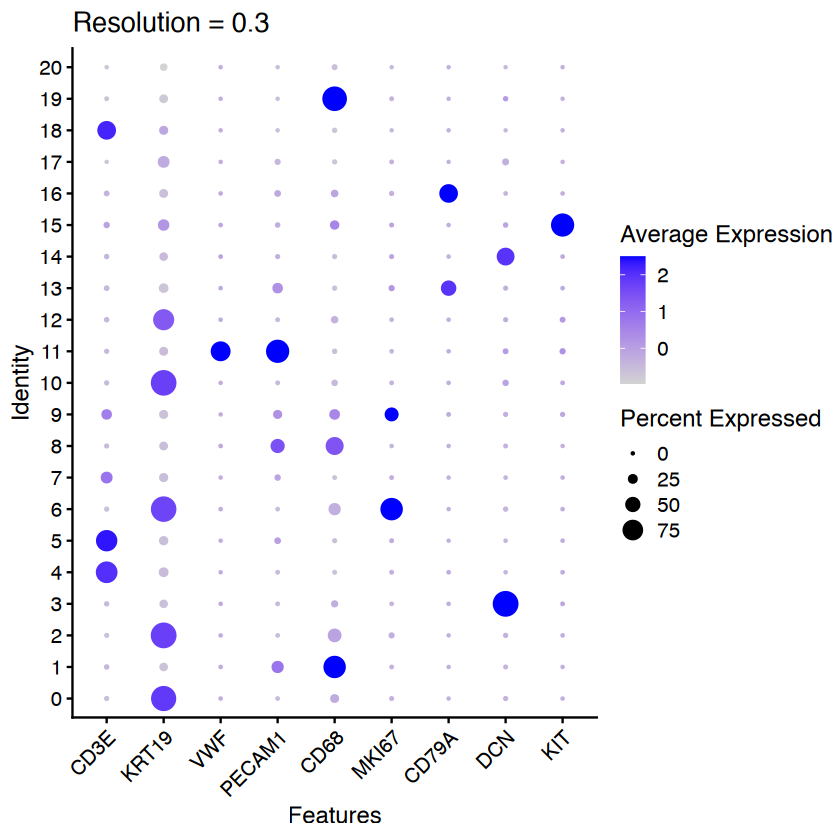

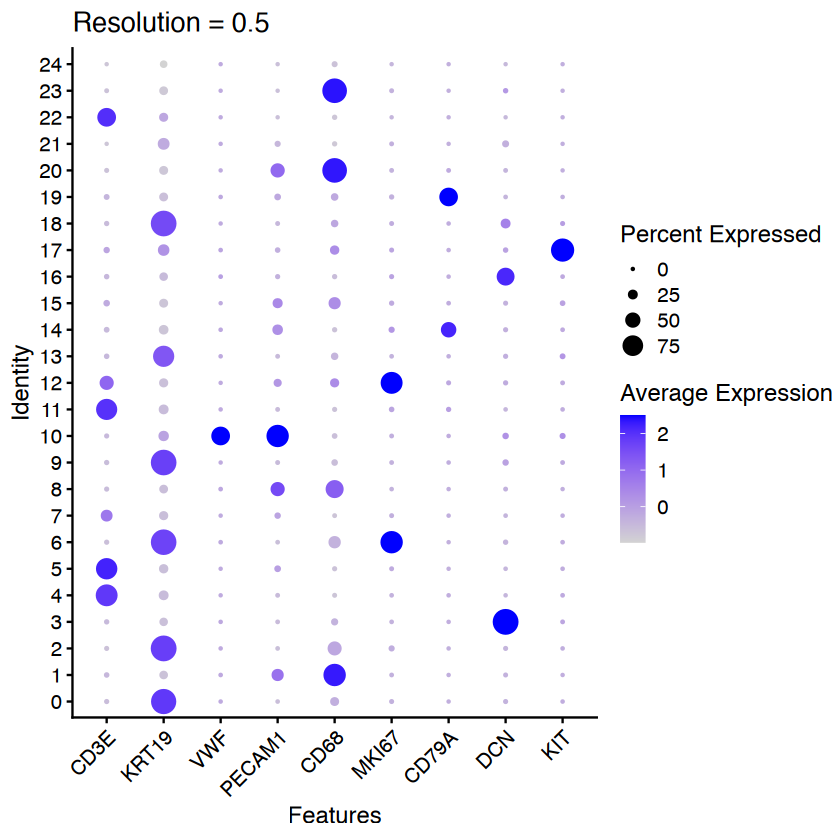

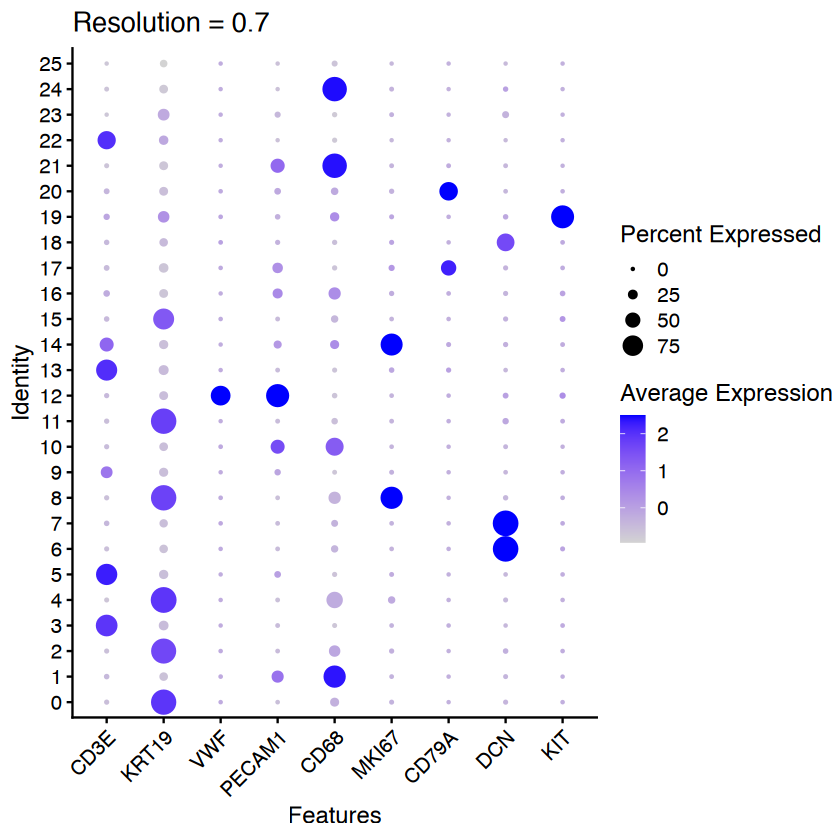

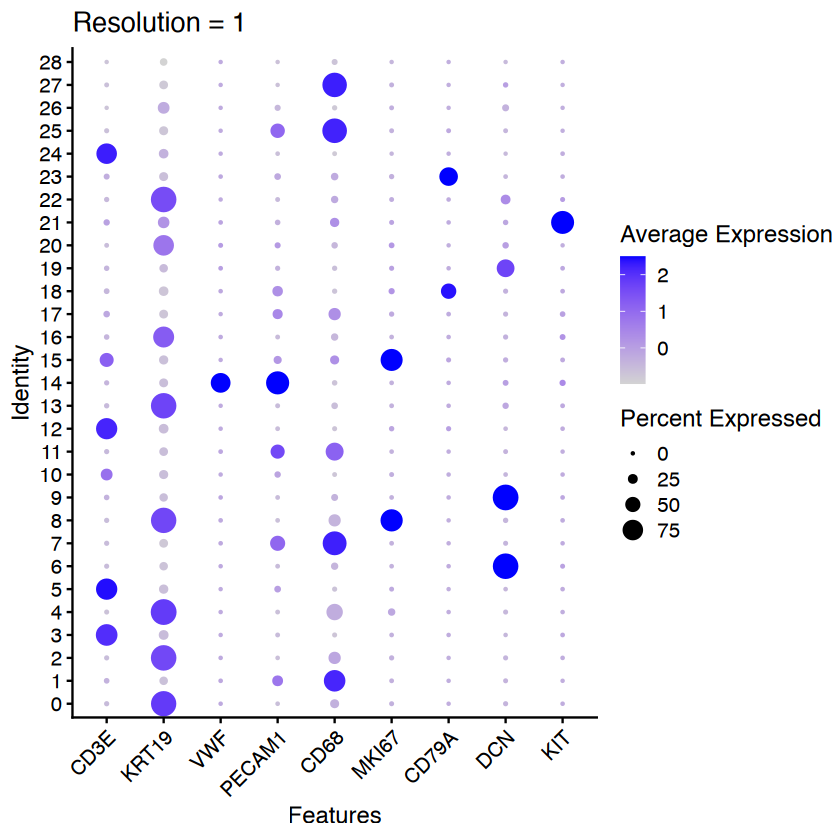

In [24]:
candidate_resolutions <- c(0.3, 0.5, 0.7, 1.0)

for (res in candidate_resolutions) {

    cluster_col <- paste0(
        "integrated_snn_res.",
        res
    )

    Idents(pdac_integrated) <- cluster_col

    p <- DotPlot(
        pdac_integrated,
        features = markers_to_check
    ) +
        RotatedAxis() +
        ggtitle(
            paste("Resolution =", res)
        )

    print(p)
}

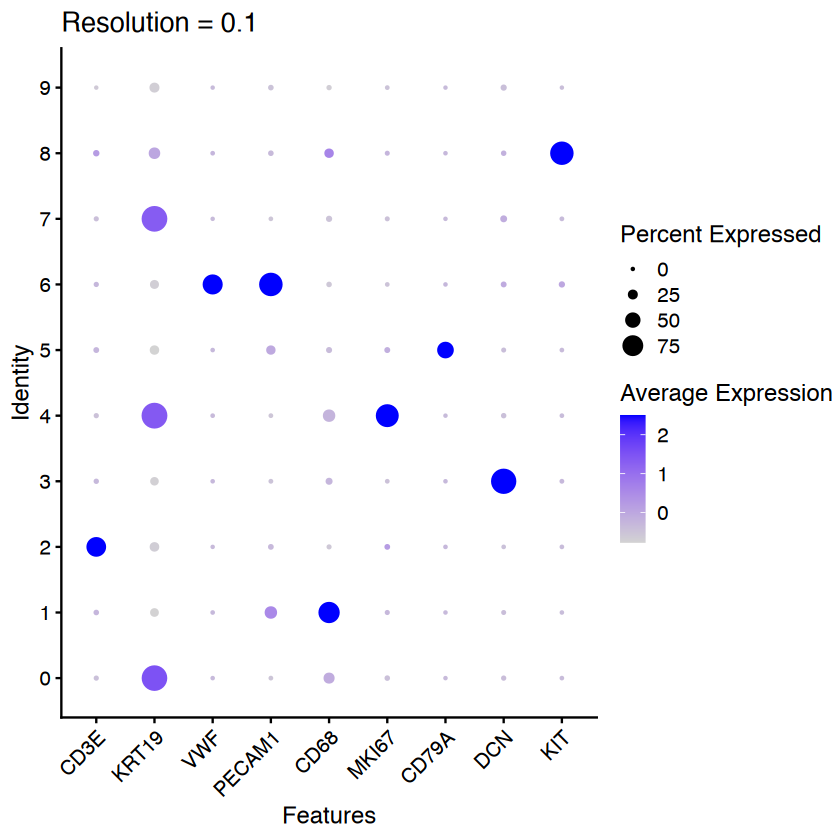

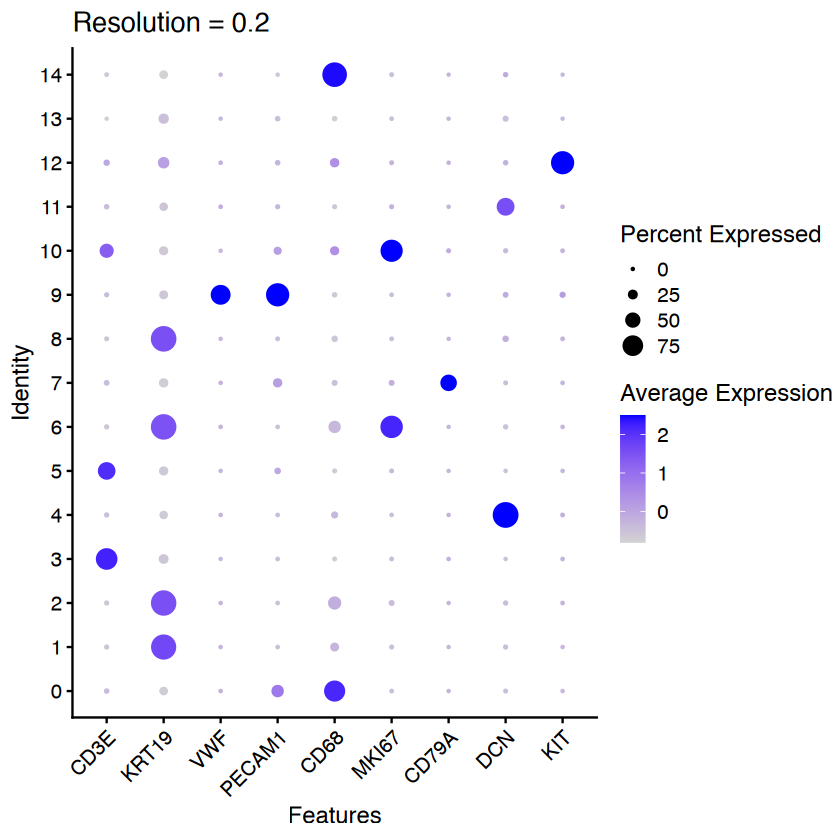

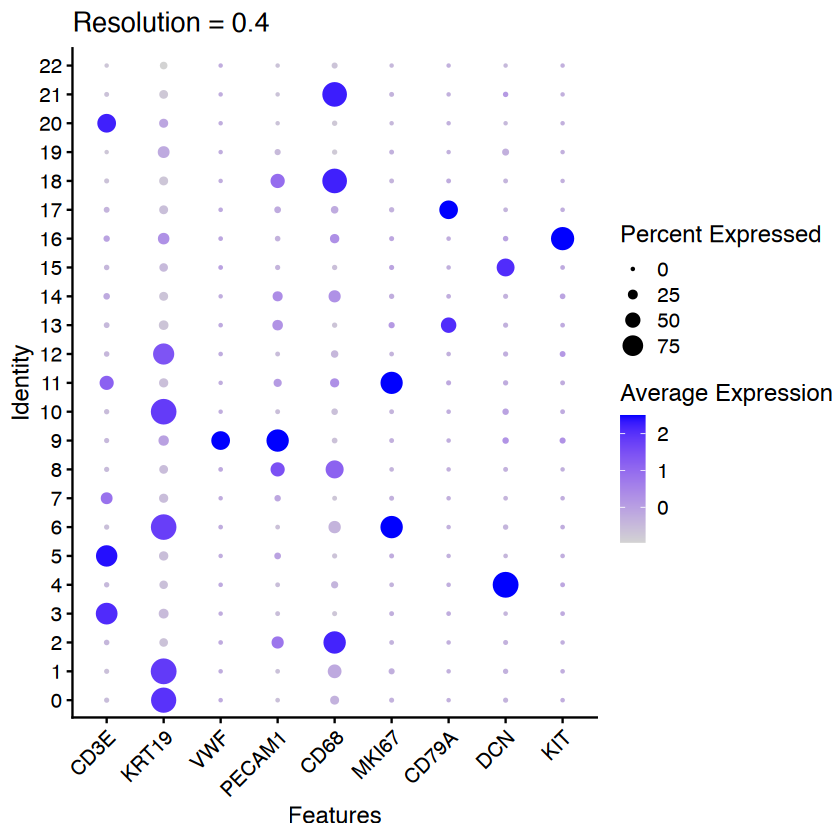

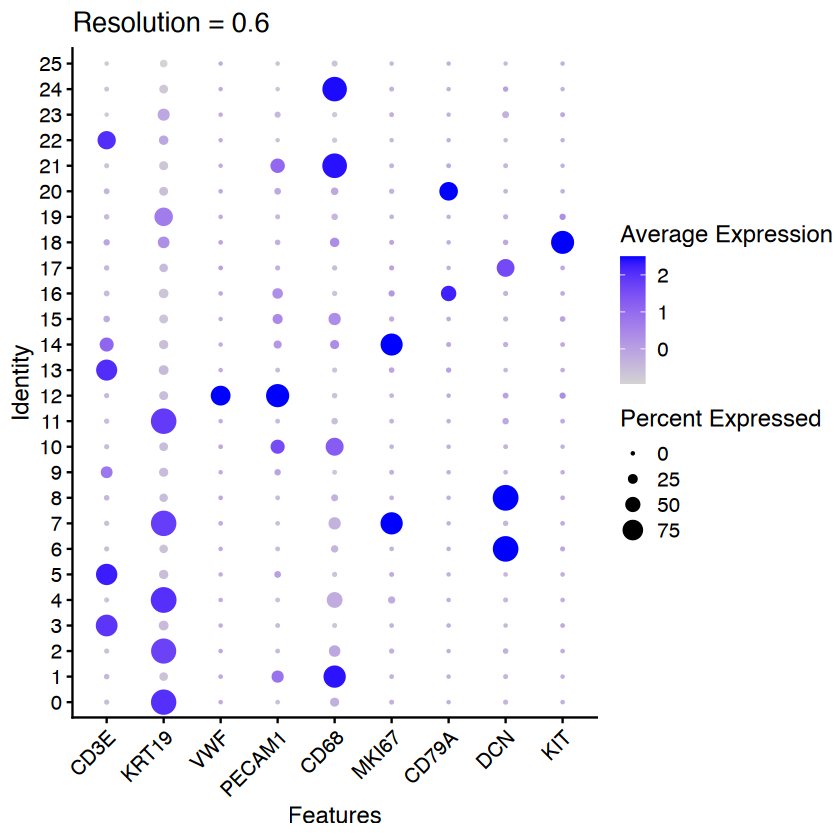

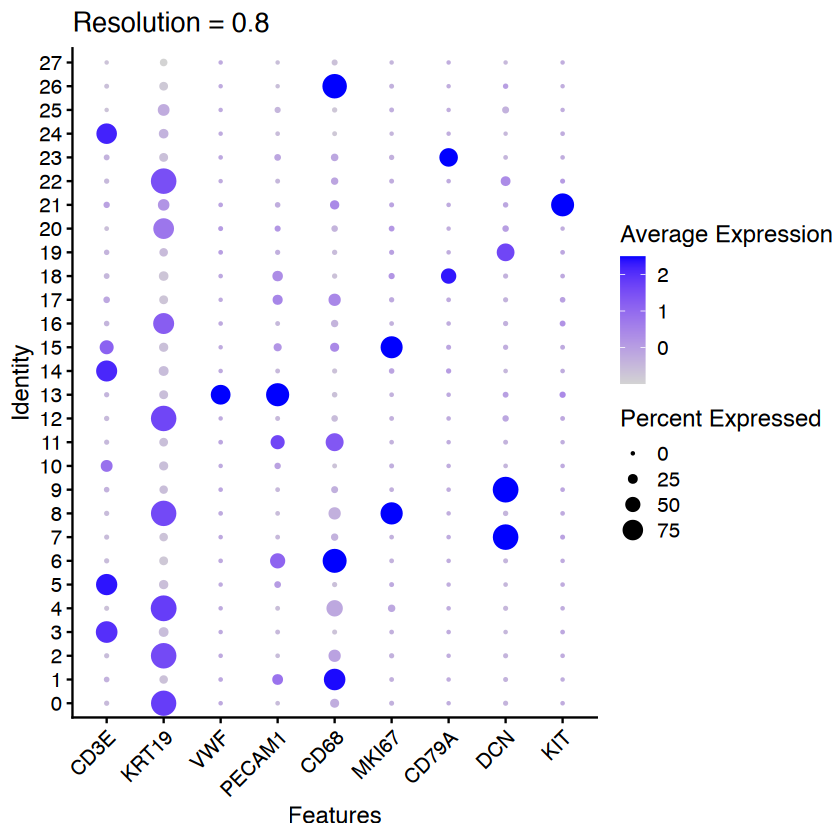

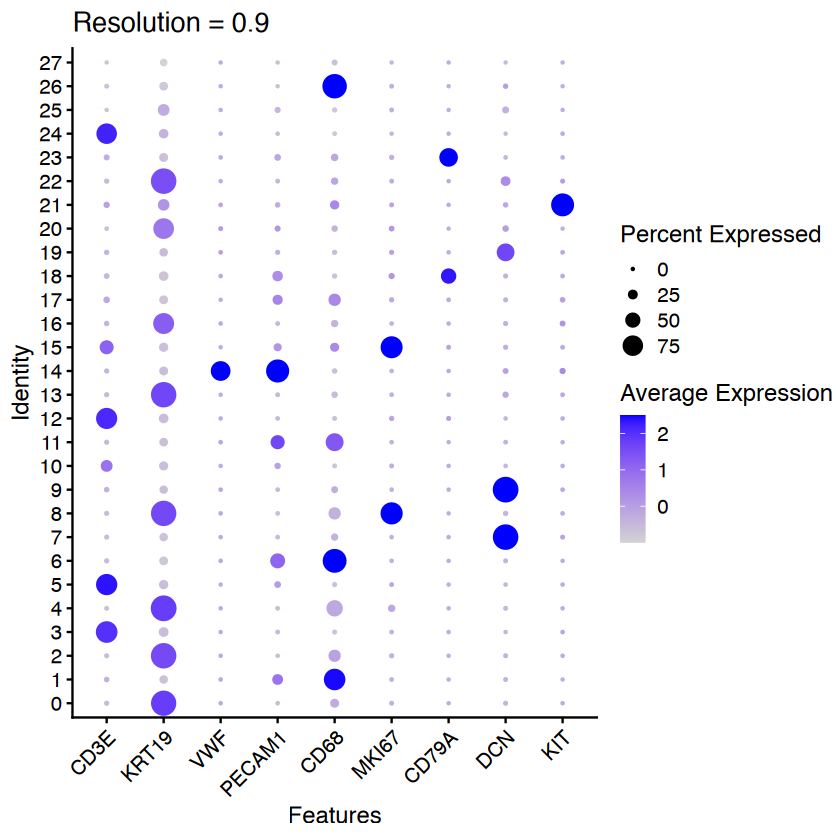

In [25]:
candidate_resolutions <- c(0.1,0.2, 0.4, 0.6, 0.8, 0.9)

for (res in candidate_resolutions) {

    cluster_col <- paste0(
        "integrated_snn_res.",
        res
    )

    Idents(pdac_integrated) <- cluster_col

    p <- DotPlot(
        pdac_integrated,
        features = markers_to_check
    ) +
        RotatedAxis() +
        ggtitle(
            paste("Resolution =", res)
        )

    print(p)
}

In [ ]:
pdac_integrated <- RunUMAP(pdac_integrated, dims=1:30, n.neighbors=30, min.dist=0.3)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
11:24:18 UMAP embedding parameters a = 0.9922 b = 1.112

11:24:18 Read 23272 rows and found 30 numeric columns

11:24:18 Using Annoy for neighbor search, n_neighbors = 30

11:24:18 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:24:20 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//Rtmp9gvziY/file58b44e990132

11:24:20 Searching Annoy index using 1 thread, search_k = 3000

11:24:24 Annoy recall = 100%

11:24:25 Commencing smooth kNN distance calibra

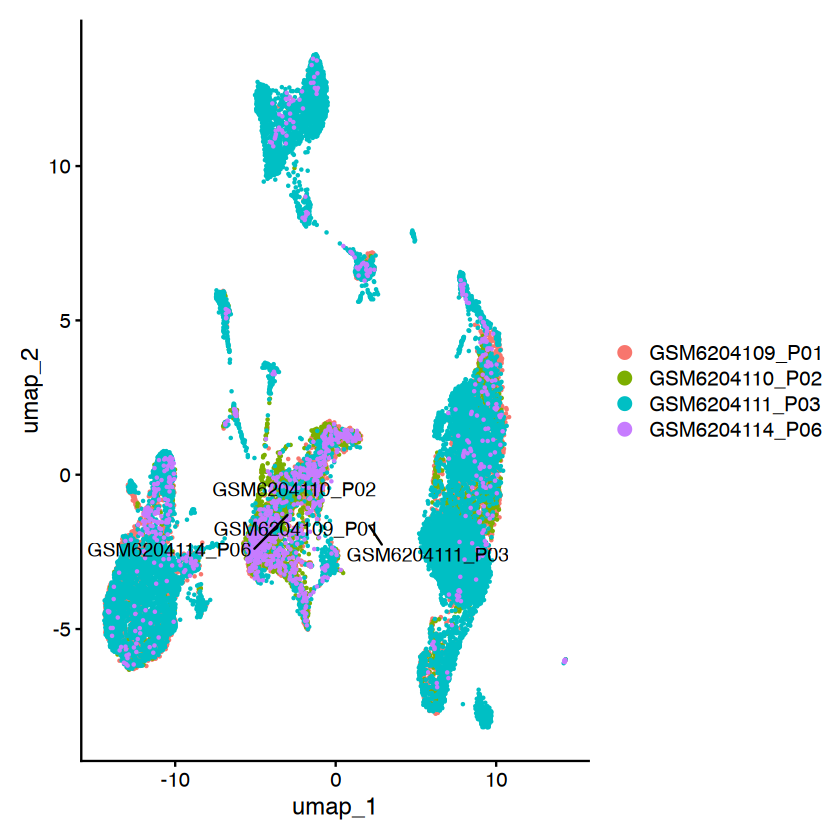

In [ ]:
DimPlot(
    pdac_integrated,
    reduction = "umap",
    label = TRUE,
    repel = TRUE,
    split.by = "sample"
)

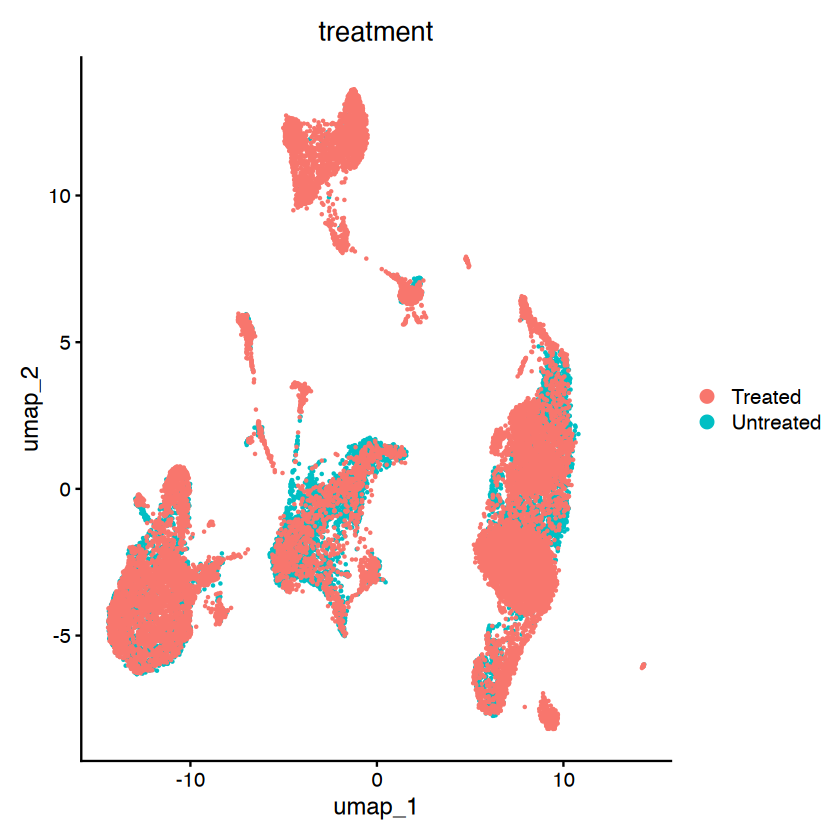

In [18]:
DimPlot(
    pdac_integrated,
    reduction = "umap",
    group.by = "treatment",
)